# Your first penalized trend

We separate noisy observations into a fitted **in-sample trend** and residuals. The finite-difference penalty controls roughness, not predictive ability. Our synthetic truth is known so we can evaluate recovery transparently.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## A reproducible signal

Construct a linear drift plus a slowly varying periodic component and white noise. A fixed seed makes every figure reproducible.

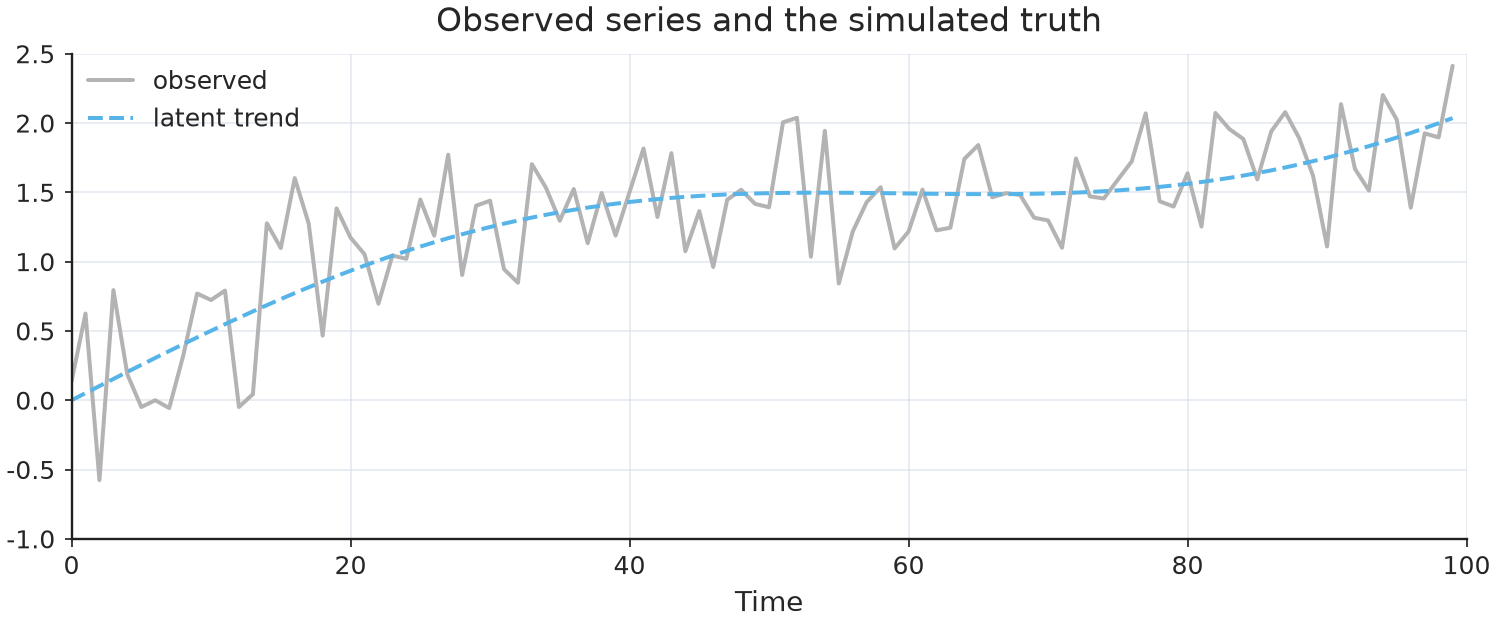

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother, plot_trend
rng=np.random.default_rng(21)
t=np.arange(100); truth=.025*t+.5*np.sin(t/19)
y=truth+rng.normal(0,.38,len(t))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(t,y,color="0.7",label="observed"); ax.plot(t,truth,label="latent trend")
ax.set(title="Observed series and the simulated truth",xlabel="Time"); ax.legend(); plt.show()

## Compare penalties

At $\lambda=0$ the trend interpolates the data; larger penalties suppress finite differences. The operation is *two-sided smoothing*: it uses the complete sample.

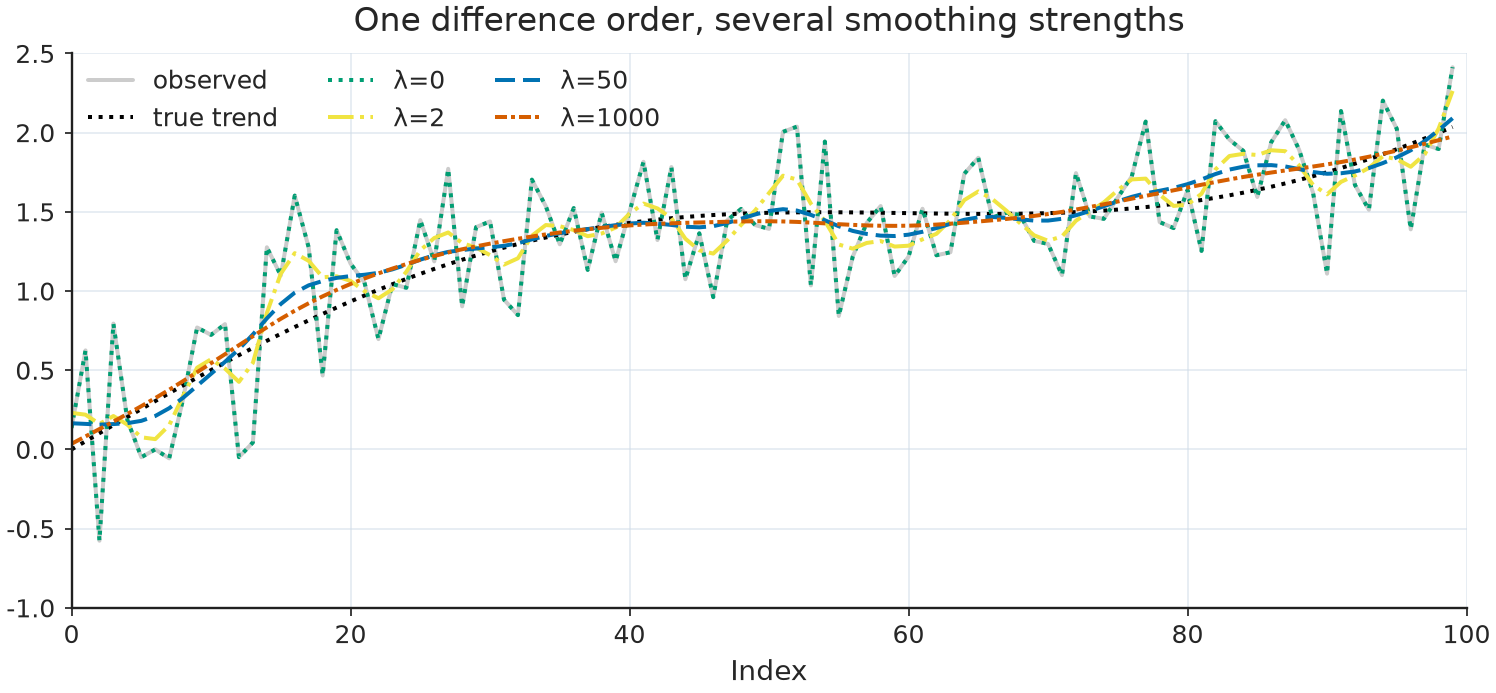

In [3]:
solver=TrendSmoother(len(y),order=2)
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(y,color="0.8",label="observed")
ax.plot(truth,color="k",ls=":",label="true trend")
for lam in [0,2,50,1000]:
    ax.plot(solver.fit(y,lambda_=lam).trend,label=f"λ={lam}")
ax.set(title="One difference order, several smoothing strengths",xlabel="Index")
ax.legend(ncol=3);plt.show()

## Residuals and roughness

The fit–smoothness trade-off can be examined through residual RMS error and the norm of second differences; neither metric alone chooses a uniquely correct trend.

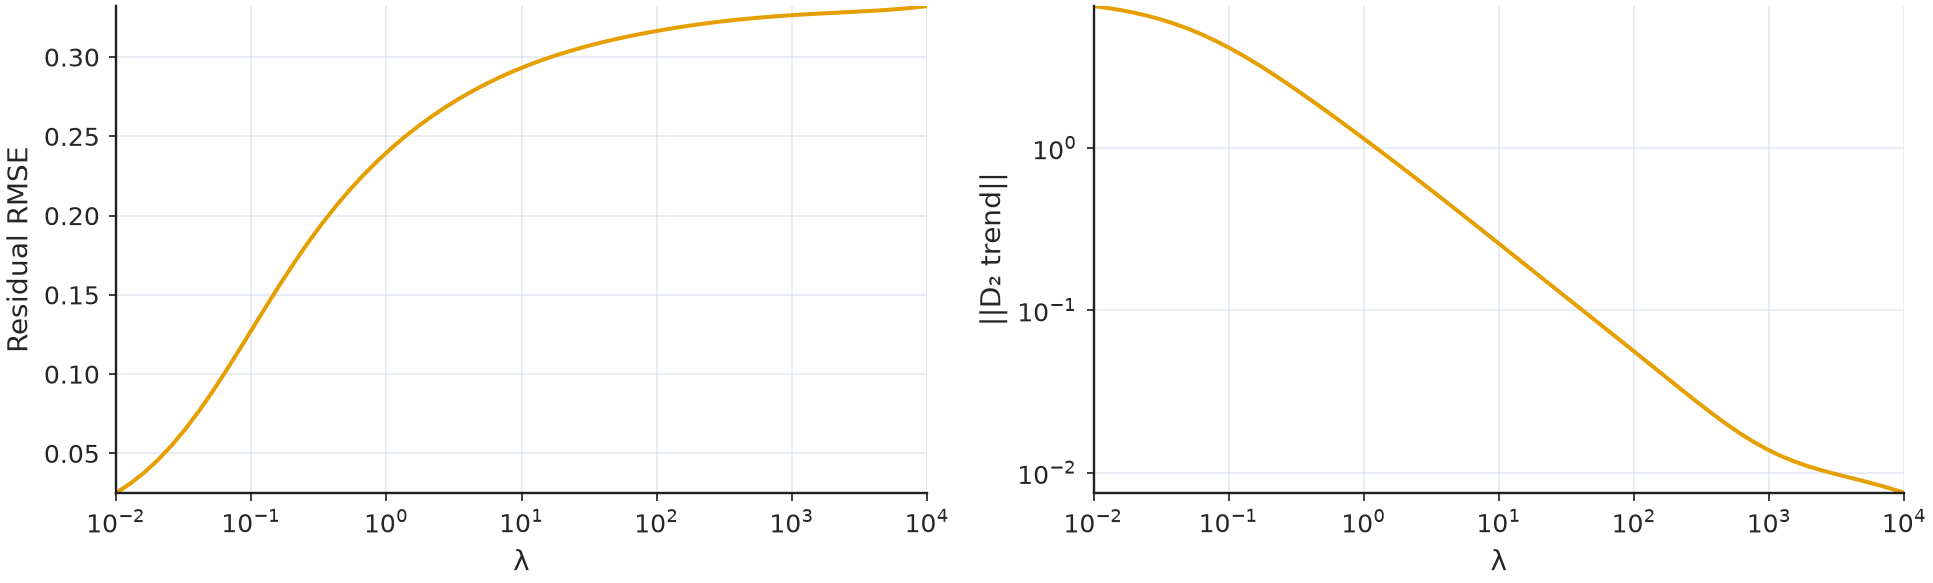

The residual RMSE generally rises as roughness decreases.


In [4]:
lambdas=np.geomspace(.01,1e4,60)
residual_rms=[];roughness=[]
for lam in lambdas:
    f=solver.fit(y,lambda_=float(lam))
    residual_rms.append(float(np.sqrt(np.mean(f.residual**2))))
    roughness.append(float(np.linalg.norm(solver.D@f.trend)))
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].semilogx(lambdas,residual_rms);ax[0].set(xlabel="λ",ylabel="Residual RMSE")
ax[1].loglog(lambdas,roughness);ax[1].set(xlabel="λ",ylabel="||D₂ trend||")
fig.tight_layout();plt.show()
print("The residual RMSE generally rises as roughness decreases.")

## Side-by-side penalty and normalized-smoothness coordinates

The following reproducible figures show the **same PLS estimator and fixed-mean CV/GCV/AICc/BIC scores** plotted against both the raw penalty $\lambda$ and normalized trace smoothness $S(\lambda)$. Both panels mark the same lowest-scoring **matched-grid** candidate. The final small timing chart runs the public GCV selector once in each coordinate. It is **illustrative only**, since the two default searches inspect different grids; controlled multi-seed timings belong to `benchmarks/criterion_coordinate_matrix.py` and `benchmarks/public_coordinate_optimizer_benchmark.py`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


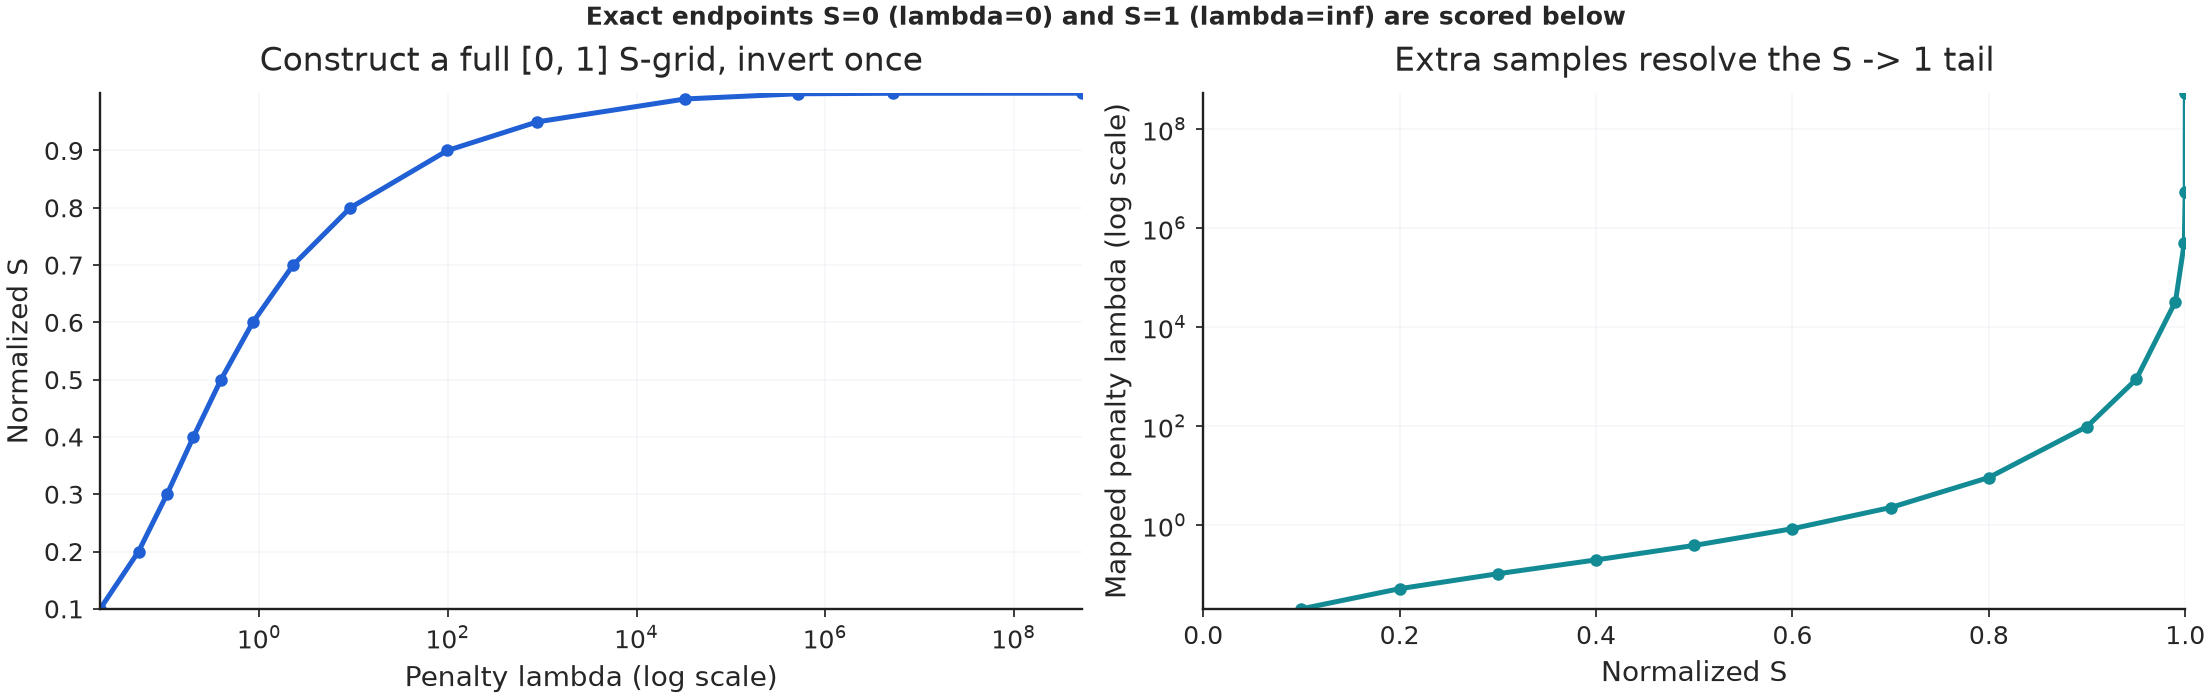

  CV: lambda=    33003.8, S=0.99, score=0.0981563
 GCV: lambda=    33003.8, S=0.99, score=0.0976726
AICC: lambda=    33003.8, S=0.99, score=-2.30289
 BIC: lambda=  0.0205109, S=0.1, score=-2.65662


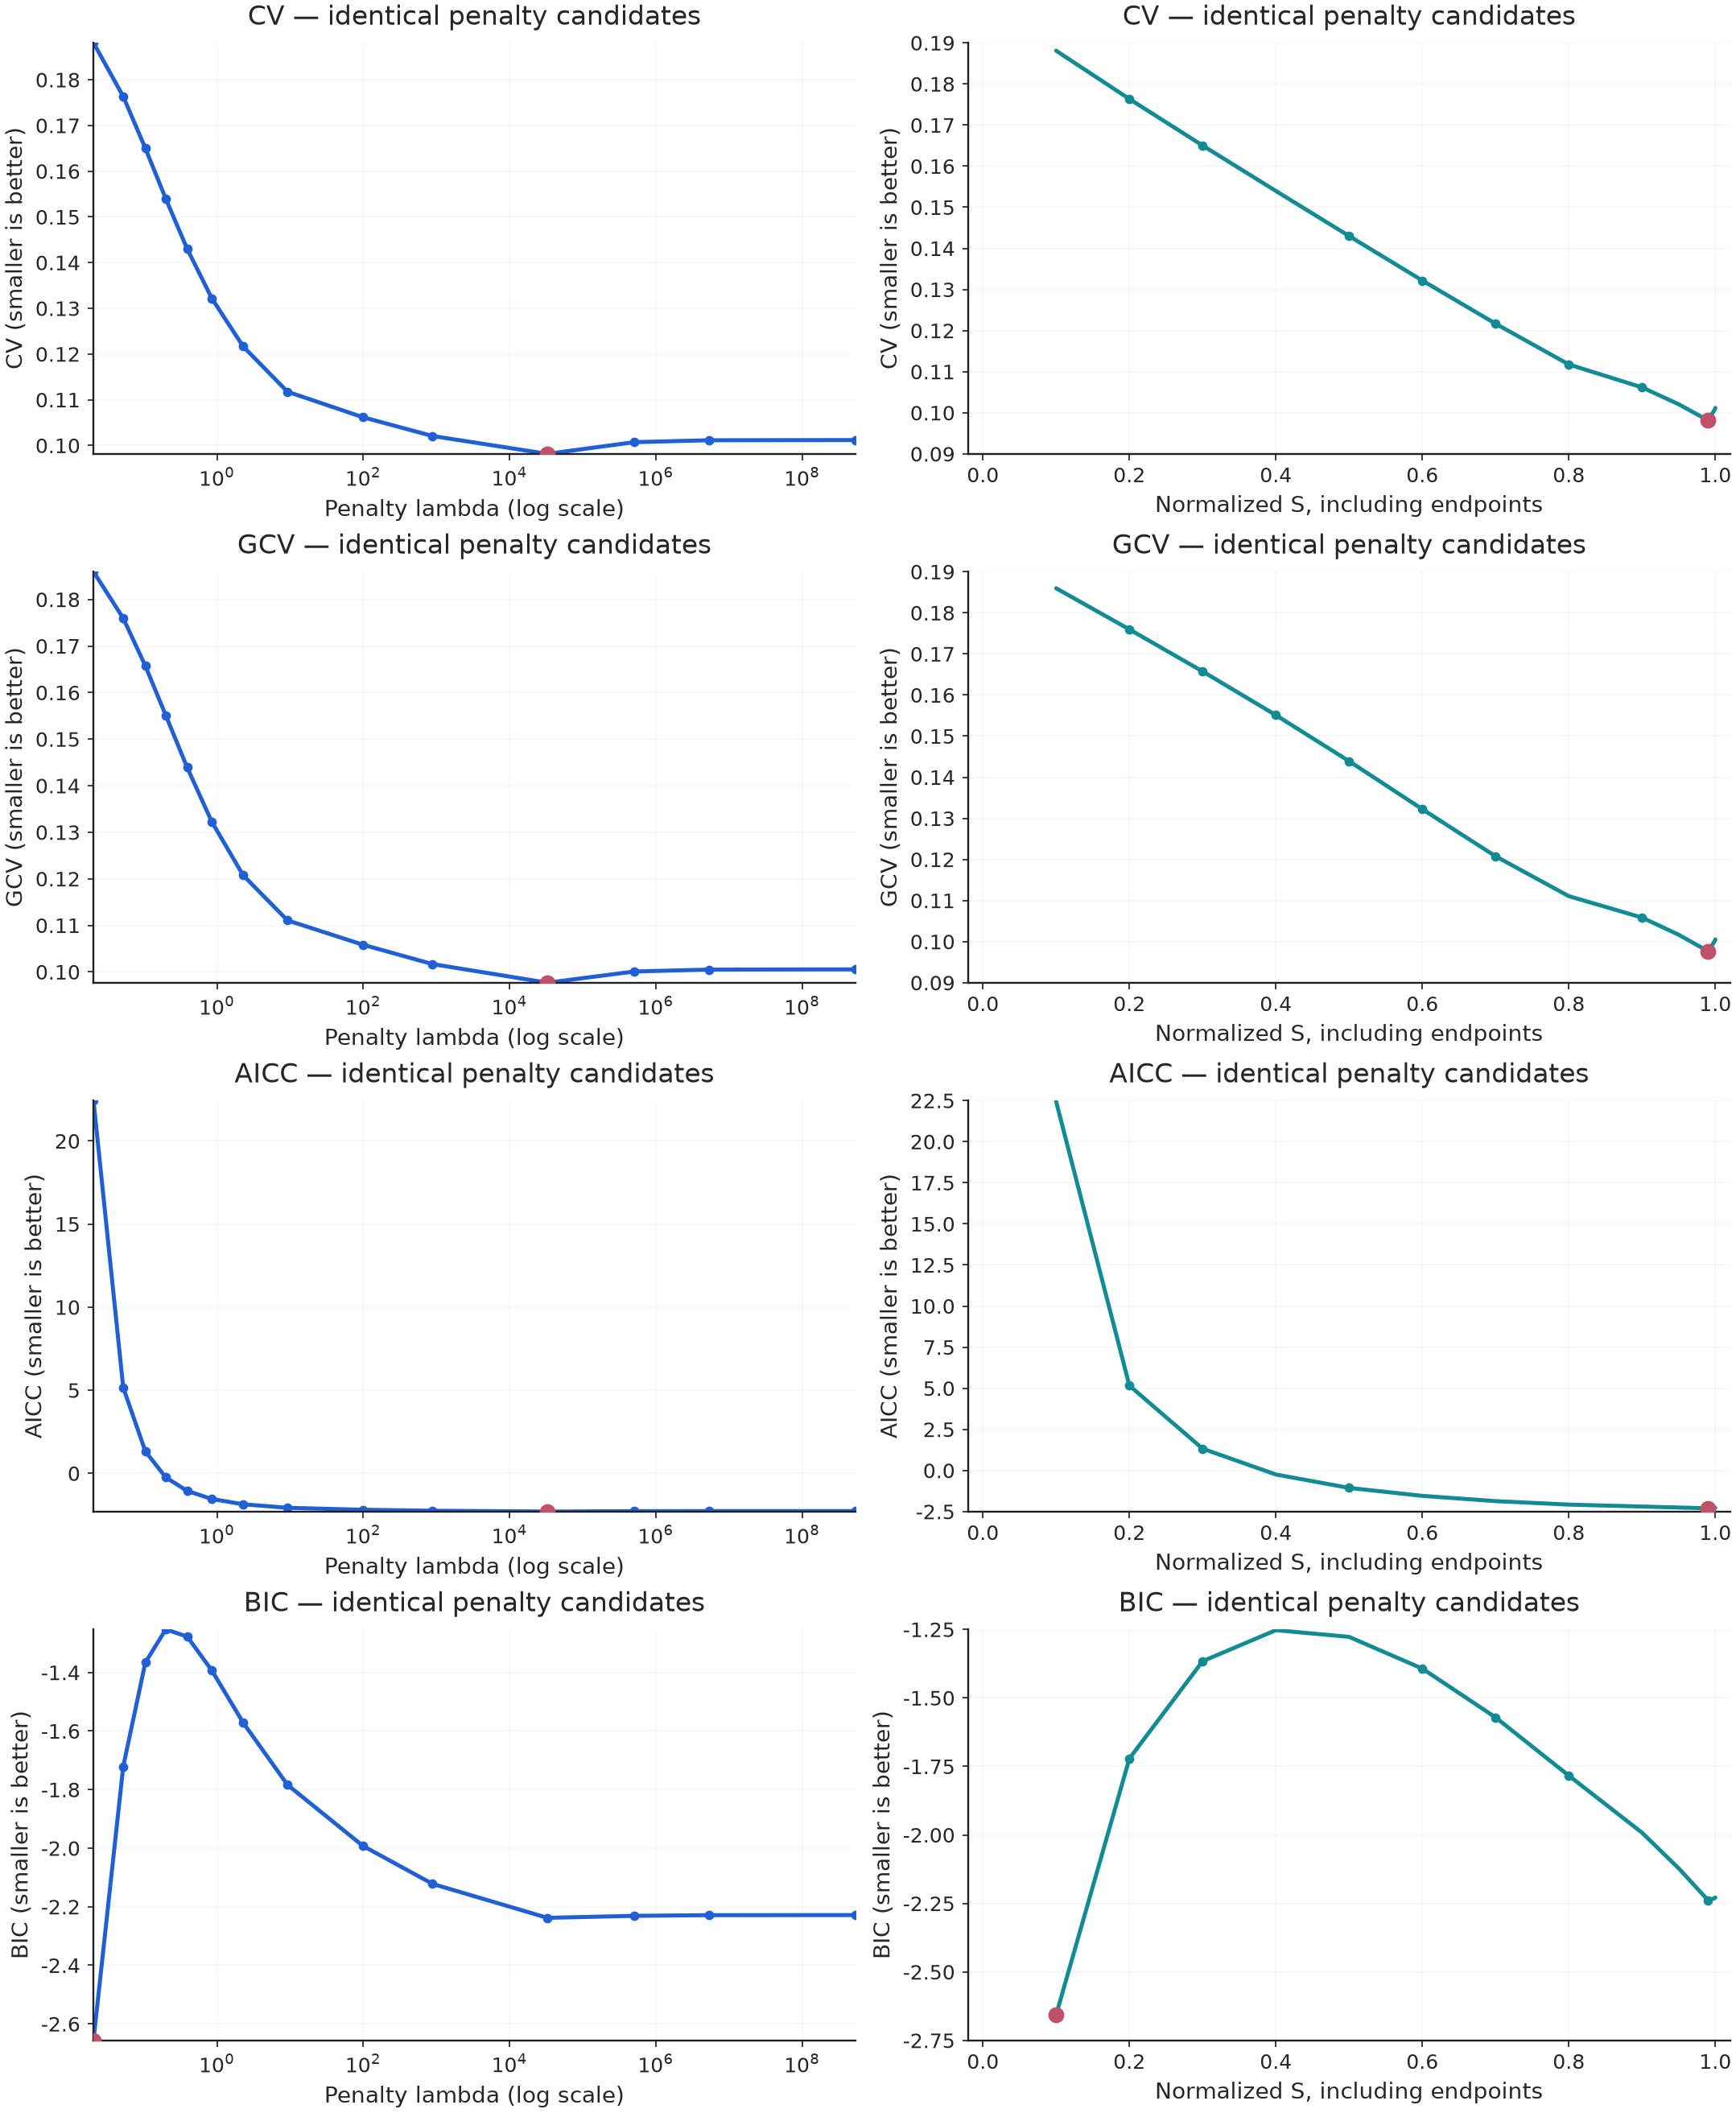

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


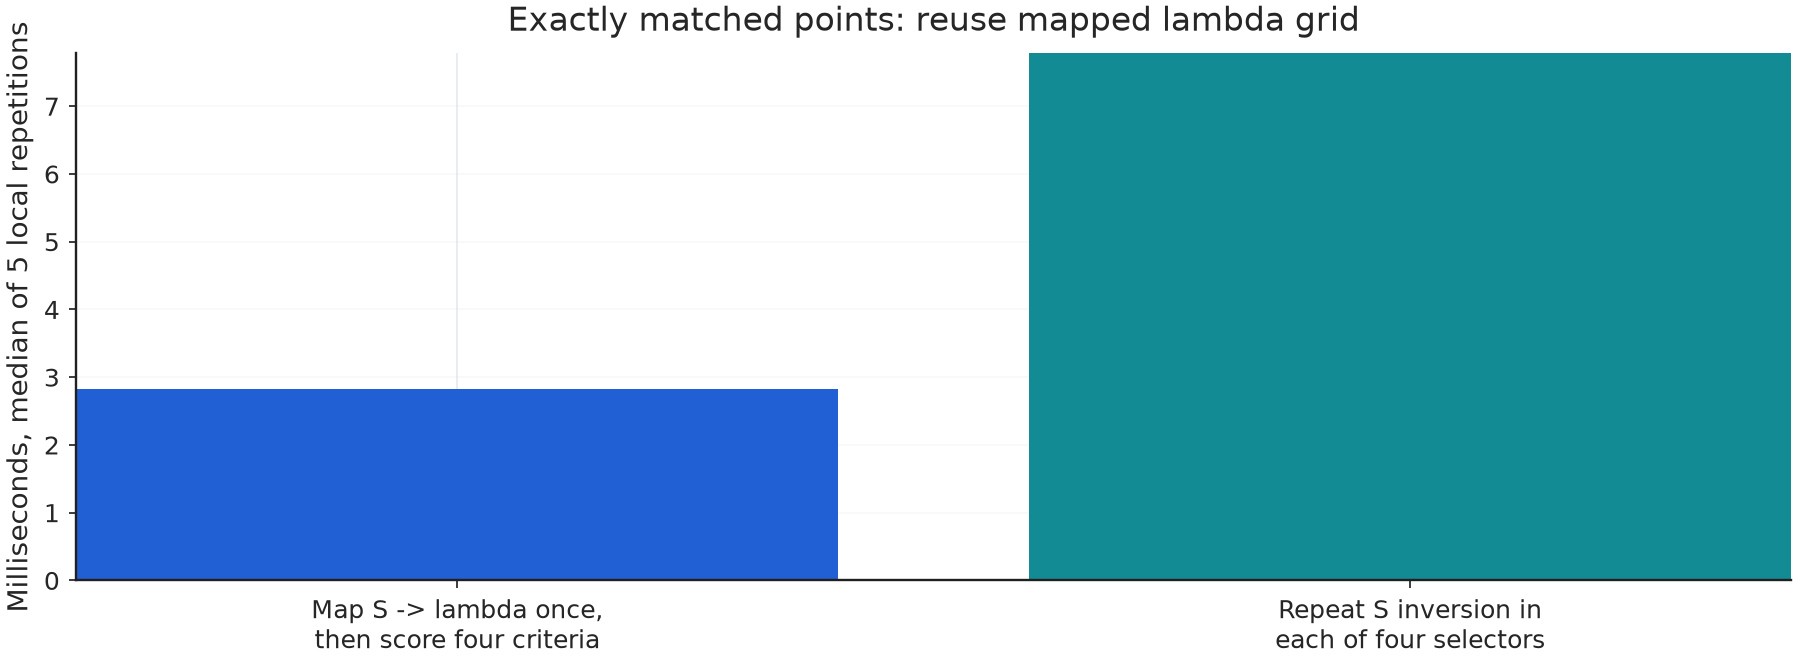

Four-criterion sweep, lambda-map-once: 2.821 ms; direct S selector (repeated mapping): 7.782 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [5]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

# Reuse notebook data when present; otherwise use a clearly labeled seeded example.
_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
